# Student Spending & Financial Stress Analysis

This notebook analyzes student spending patterns to identify the primary drivers of financial stress.  
The goal is to determine whether financial stress is caused by discretionary overspending or unavoidable essential expenses, and to derive actionable insights for student-focused financial products.

---

## Data Loading & Overview

The dataset contains demographic information, income details, and categorized spending data for approximately 1,000 students.  
We begin by loading the dataset and performing basic structural checks.


In [34]:
import pandas as pd 
df = pd.read_csv("../Data/student-spending-habits.csv")
print(df.head())


   Unnamed: 0  age      gender year_in_school             major  \
0           0   19  Non-binary       Freshman        Psychology   
1           1   24      Female         Junior         Economics   
2           2   24  Non-binary         Junior         Economics   
3           3   23      Female         Senior  Computer Science   
4           4   20      Female         Senior  Computer Science   

   monthly_income  financial_aid  tuition  housing  food  transportation  \
0             958            270     5939      709   296             123   
1            1006            875     4908      557   365              85   
2             734            928     3051      666   220             137   
3             617            265     4935      652   289             114   
4             810            522     3887      825   372             168   

   books_supplies  entertainment  personal_care  technology  health_wellness  \
0             188             41             78         134 

In [35]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Unnamed: 0                1000 non-null   int64 
 1   age                       1000 non-null   int64 
 2   gender                    1000 non-null   object
 3   year_in_school            1000 non-null   object
 4   major                     1000 non-null   object
 5   monthly_income            1000 non-null   int64 
 6   financial_aid             1000 non-null   int64 
 7   tuition                   1000 non-null   int64 
 8   housing                   1000 non-null   int64 
 9   food                      1000 non-null   int64 
 10  transportation            1000 non-null   int64 
 11  books_supplies            1000 non-null   int64 
 12  entertainment             1000 non-null   int64 
 13  personal_care             1000 non-null   int64 
 14  technology               

In [36]:
df.isnull().sum()

Unnamed: 0                  0
age                         0
gender                      0
year_in_school              0
major                       0
monthly_income              0
financial_aid               0
tuition                     0
housing                     0
food                        0
transportation              0
books_supplies              0
entertainment               0
personal_care               0
technology                  0
health_wellness             0
miscellaneous               0
preferred_payment_method    0
dtype: int64

In [37]:
df.describe()

,Unnamed: 0,age,monthly_income,financial_aid,tuition,housing,food,transportation,books_supplies,entertainment,personal_care,technology,health_wellness,miscellaneous
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,21.675000,1020.650000,504.771000,4520.395000,696.00600,252.642000,124.63700,174.761000,84.814000,60.699000,178.304000,114.310000,108.910000
std,288.819436,2.322664,293.841161,287.092575,860.657944,171.21862,86.949606,43.55799,72.404518,37.970451,22.898007,71.744441,49.591544,52.412221
min,0.000000,18.000000,501.000000,0.000000,3003.000000,401.00000,100.000000,50.00000,50.000000,20.000000,20.000000,50.000000,30.000000,20.000000
25%,249.750000,20.000000,770.750000,261.000000,3779.750000,538.75000,175.000000,88.00000,112.000000,54.000000,41.000000,114.000000,73.000000,63.750000
50%,499.500000,22.000000,1021.000000,513.000000,4547.500000,704.50000,255.000000,123.00000,175.000000,86.000000,62.000000,178.000000,115.000000,110.000000
75%,749.250000,24.000000,1288.250000,751.500000,5285.000000,837.25000,330.000000,162.25000,238.000000,116.000000,80.000000,241.000000,158.000000,153.000000
max,999.000000,25.000000,1500.000000,1000.000000,6000.000000,1000.00000,400.000000,200.00000,300.000000,150.000000,100.000000,300.000000,200.000000,200.000000


In [38]:
df.drop(columns=['Unnamed: 0'], inplace = True)

In [39]:
df.columns


Index(['age', 'gender', 'year_in_school', 'major', 'monthly_income',
       'financial_aid', 'tuition', 'housing', 'food', 'transportation',
       'books_supplies', 'entertainment', 'personal_care', 'technology',
       'health_wellness', 'miscellaneous', 'preferred_payment_method'],
      dtype='object')

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   age                       1000 non-null   int64 
 1   gender                    1000 non-null   object
 2   year_in_school            1000 non-null   object
 3   major                     1000 non-null   object
 4   monthly_income            1000 non-null   int64 
 5   financial_aid             1000 non-null   int64 
 6   tuition                   1000 non-null   int64 
 7   housing                   1000 non-null   int64 
 8   food                      1000 non-null   int64 
 9   transportation            1000 non-null   int64 
 10  books_supplies            1000 non-null   int64 
 11  entertainment             1000 non-null   int64 
 12  personal_care             1000 non-null   int64 
 13  technology                1000 non-null   int64 
 14  health_wellness          

In [41]:
df.columns

Index(['age', 'gender', 'year_in_school', 'major', 'monthly_income',
       'financial_aid', 'tuition', 'housing', 'food', 'transportation',
       'books_supplies', 'entertainment', 'personal_care', 'technology',
       'health_wellness', 'miscellaneous', 'preferred_payment_method'],
      dtype='object')

## Defining Financial Stress

To analyze financial stress in a measurable way, we define a student as financially stressed if essential expenses exceed 70% of their effective income.  
Effective income is calculated as the sum of monthly income and financial aid.

This definition focuses on structural cost pressure rather than discretionary spending behavior.


In [42]:
essential_cols = [
    "housing",
    "food",
    "transportation",
    "health_wellness",
    "books_supplies"
]

df["essential_expenses"] = df[essential_cols].sum(axis=1)
df["effective_income"] = df["monthly_income"] + df["financial_aid"]


In [43]:
df["essential_ratio"] = df["essential_expenses"] / df["effective_income"]


In [44]:
df["financial_stress"] = df["essential_ratio"] > 0.7

In [45]:
df["financial_stress"].value_counts(normalize=True) * 100

financial_stress
True     78.7
False    21.3
Name: proportion, dtype: float64

In [46]:
for threshold in [0.6, 0.7, 0.8]:
    stressed_pct = (df["essential_ratio"] > threshold).mean() * 100
    print(f"Threshold {threshold}: {stressed_pct:.1f}% stressed")


Threshold 0.6: 90.4% stressed
Threshold 0.7: 78.7% stressed
Threshold 0.8: 63.1% stressed


## Income-Based Segmentation

Students are segmented into income bands using quantile-based grouping.  
This allows for fair comparison of financial stress levels across relative income groups rather than absolute income values.


In [47]:
df["income_band"] = pd.qcut(df["monthly_income"], q=4, labels=["Low", "lower-mid", "Upper-mid", "High"])

In [48]:
df.columns


Index(['age', 'gender', 'year_in_school', 'major', 'monthly_income',
       'financial_aid', 'tuition', 'housing', 'food', 'transportation',
       'books_supplies', 'entertainment', 'personal_care', 'technology',
       'health_wellness', 'miscellaneous', 'preferred_payment_method',
       'essential_expenses', 'effective_income', 'essential_ratio',
       'financial_stress', 'income_band'],
      dtype='object')

In [ ]:
income_stress = df.groupby("income_band")["financial_stress"].mean() * 100




In [50]:
df.tail()

,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,...,personal_care,technology,health_wellness,miscellaneous,preferred_payment_method,essential_expenses,effective_income,essential_ratio,financial_stress,income_band
995,22,Female,Senior,Biology,1346,520,3688,969,152,194,...,38,252,65,163,Cash,1531,1866,0.820472,True,High
996,19,Female,Senior,Biology,1407,560,3380,508,265,52,...,98,274,84,135,Mobile Payment App,1115,1967,0.566853,False,High
997,20,Male,Junior,Economics,957,393,3497,723,339,139,...,46,284,57,28,Mobile Payment App,1327,1350,0.982963,True,lower-mid
998,22,Non-binary,Senior,Economics,1174,612,3649,543,237,123,...,90,190,101,65,Mobile Payment App,1204,1786,0.674132,False,Upper-mid
999,24,Non-binary,Sophomore,Computer Science,541,640,5965,609,270,191,...,43,281,88,145,Cash,1373,1181,1.162574,True,Low


C:\Users\sandeep\AppData\Local\Temp\ipykernel_11260\650558859.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  income_stress = df.groupby("income_band")["financial_stress"].mean() * 100


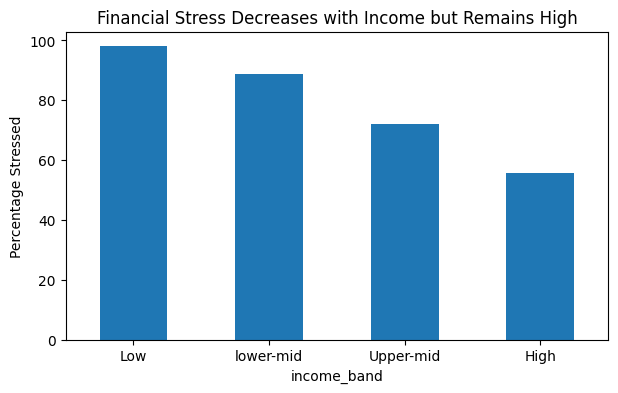

In [51]:
income_stress = df.groupby("income_band")["financial_stress"].mean() * 100

plt.figure(figsize=(7, 4))
income_stress.plot(kind="bar")
plt.ylabel("Percentage Stressed")
plt.title("Financial Stress Decreases with Income but Remains High")
plt.xticks(rotation=0)
plt.show()

### Insight
Financial stress declines as income increases; however, even students in the highest income band experience substantial levels of financial stress.


## Financial Stress Across Academic Years

We analyze how financial stress varies by year of study to understand whether financial pressure increases as students progress through university.


In [52]:
df.groupby("year_in_school")["financial_stress"].mean() * 100

year_in_school
Freshman     73.913043
Junior       80.971660
Senior       81.102362
Sophomore    78.861789
Name: financial_stress, dtype: float64

In [53]:
df.columns


Index(['age', 'gender', 'year_in_school', 'major', 'monthly_income',
       'financial_aid', 'tuition', 'housing', 'food', 'transportation',
       'books_supplies', 'entertainment', 'personal_care', 'technology',
       'health_wellness', 'miscellaneous', 'preferred_payment_method',
       'essential_expenses', 'effective_income', 'essential_ratio',
       'financial_stress', 'income_band'],
      dtype='object')

In [54]:
non_essential_cols = ["entertainment", "personal_care", "miscellaneous", "technology"]


In [55]:
df["non_essential_expenses"] = df[non_essential_cols].sum(axis=1)

## Spending Behavior Analysis

To understand the drivers of financial stress, we compare essential and non-essential spending between financially stressed and non-stressed students.  
This helps determine whether stress is caused by discretionary overspending or unavoidable living costs.


In [56]:
spending_summary = df.groupby("financial_stress")[["essential_expenses", "non_essential_expenses"]].mean()
print(spending_summary)

                  essential_expenses  non_essential_expenses
financial_stress                                            
False                    1191.826291              430.985915
True                     1408.509530              433.198221


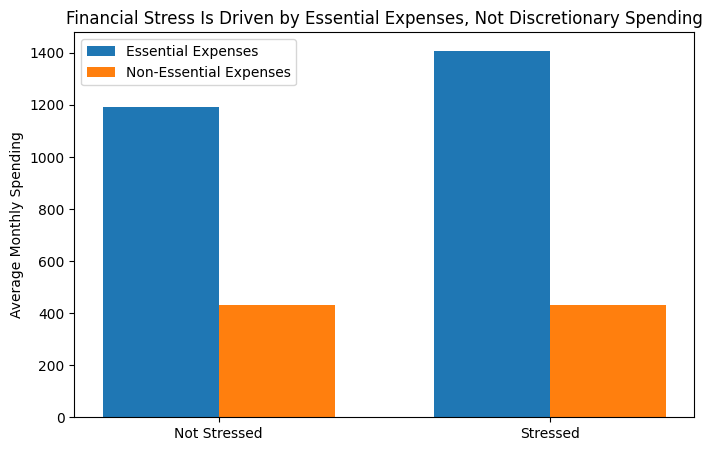

In [57]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["Not Stressed", "Stressed"]
essential = spending_summary["essential_expenses"].values
non_essential = spending_summary["non_essential_expenses"].values

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, essential, width, label="Essential Expenses")
plt.bar(x + width/2, non_essential, width, label="Non-Essential Expenses")

plt.xticks(x, labels)
plt.ylabel("Average Monthly Spending")
plt.title("Financial Stress Is Driven by Essential Expenses, Not Discretionary Spending")
plt.legend()

plt.show()


### Insight
Financially stressed students exhibit significantly higher essential expenses compared to non-stressed students, while non-essential spending remains nearly identical across both groups.  
This indicates that financial stress is primarily driven by unavoidable living costs rather than discretionary overspending.

---


In [58]:
df.head()

,age,gender,year_in_school,major,monthly_income,financial_aid,tuition,housing,food,transportation,...,technology,health_wellness,miscellaneous,preferred_payment_method,essential_expenses,effective_income,essential_ratio,financial_stress,income_band,non_essential_expenses
0,19,Non-binary,Freshman,Psychology,958,270,5939,709,296,123,...,134,127,72,Credit/Debit Card,1443,1228,1.175081,True,lower-mid,325
1,24,Female,Junior,Economics,1006,875,4908,557,365,85,...,226,129,68,Credit/Debit Card,1388,1881,0.737905,True,lower-mid,460
2,24,Non-binary,Junior,Economics,734,928,3051,666,220,137,...,239,112,133,Cash,1234,1662,0.742479,True,Low,525
3,23,Female,Senior,Computer Science,617,265,4935,652,289,114,...,163,105,55,Mobile Payment App,1383,882,1.568027,True,Low,347
4,20,Female,Senior,Computer Science,810,522,3887,825,372,168,...,88,71,104,Credit/Debit Card,1630,1332,1.223724,True,lower-mid,311


## Key Takeaways

- Financial stress among students is widespread and persists across income levels
- Stress increases in later academic years as financial independence grows
- Essential expenses, not discretionary spending, are the primary driver of financial stress
- Effective financial tools should focus on managing unavoidable costs rather than restricting lifestyle choices
